# Cross-Station Meta-Learning for Dynamic Combination of Monthly Rainfall Forecasts

This notebook runs the whole experiment of the manuscript, from raw data to tables and figures:

1. **Rainfall data.** SILO daily rainfall for 15 stations (1926–2025) is converted to monthly totals with an observation mask.
2. **Climate indices.** Niño3.4 (ERSST v5), DMI (HadISST), and SOI (CRU).
3. **Base models.** SARIMA, SVR, XGBoost, LSTM, GRU, and four VMD/wavelet hybrids, retrained every 5 years from 1961. Two rolling climatologies are added, giving an 11-member pool.
4. **Meta-learner gates.** Local gates per station (L-G3, L-G4), cross-station global gates (GG3, GG4), and a transfer gate trained without the test stations (GG4-T).
5. **Evaluation.** NSE, RMSE, MAE, per-station Diebold–Mariano tests with the Holm correction, and cross-station panel DM tests with squared and absolute errors.
6. **Manuscript Tables 1–6 and Figures 1–4**, the full experiment report, and a check of the figures quoted in the manuscript.

**Two ways to run**

| Mode | Settings | Time (16-core CPU) |
|---|---|---|
| Reproduction (default) | `RETRAIN_BASE_MODELS = False`, `RETRAIN_GATES = False` | ≈ 3 minutes |
| Full pipeline | both switches `True` | ≈ 25 minutes with 15 parallel processes; ≈ 4–5 hours with 1 process |

Reproduction mode uses the base-model and gate outputs stored in `results/`, then rebuilds the meta-dataset, the evaluation, the tables, and the figures. The full mode retrains every model. On different hardware or library versions, retraining can produce small numerical differences.

## 0. Settings

In [1]:
import os
RETRAIN_BASE_MODELS = False   # True: retrain the 9 base models x 15 stations (rolling retraining 1961-2021)
RETRAIN_GATES = False         # True: retrain the local, global, and transfer gates (3 seeds per gate)
REBUILD_DATA = True           # True: recompute the monthly aggregation and the climate indices from the raw data
WORKERS = max(1, (os.cpu_count() or 2) - 1)   # number of parallel processes for training

In [2]:
import sys, json, glob, shutil, subprocess, time, platform
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC, RESULTS, PROCESSED = ROOT / "src", ROOT / "results", ROOT / "data" / "processed"
sys.path.insert(0, str(SRC))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

def run_script(*args, env_extra=None):
    # Runs a script in src/ as a separate process and prints its output line by line.
    env = {**os.environ, "WORKERS": str(WORKERS), "PYTHONIOENCODING": "utf-8", **(env_extra or {})}
    p = subprocess.Popen([sys.executable, str(SRC / args[0]), *args[1:]], cwd=ROOT, env=env,
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, encoding="utf-8", errors="replace")
    ignore = ("WARNING", "I0000", "W0000", "oneDNN", "cpu_feature_guard", "To enable the following", "absl::")
    for line in p.stdout:
        if not any(a in line for a in ignore): print(line, end="")
    if p.wait() != 0: raise RuntimeError(f"{args[0]} failed (exit code {p.returncode})")

def read_bytes(path): return open(path, "rb").read() if Path(path).exists() else None

def _max_diff(a, b):   # maximum numerical difference between two JSON structures (inf if the structures differ)
    if isinstance(a, dict): return max([_max_diff(a[k], b[k]) for k in a], default=0.0) if isinstance(b, dict) and a.keys() == b.keys() else np.inf
    if isinstance(a, list): return max([_max_diff(u, v) for u, v in zip(a, b)], default=0.0) if isinstance(b, list) and len(a) == len(b) else np.inf
    if isinstance(a, (int, float)) and isinstance(b, (int, float)): return 0.0 if (a != a and b != b) else abs(a - b)
    return 0.0 if a == b else np.inf

def compare(path, previous):
    # Compares a newly written file with the version in the repository (binary content first, then numerical values).
    if previous is None: return "newly created"
    new = open(path, "rb").read(); norm = lambda x: x.replace(b"\r\n", b"\n")
    if norm(new) == norm(previous): return "identical to the repository version"
    import io
    try:
        if str(path).endswith(".json"): d = _max_diff(json.loads(previous), json.loads(new))
        else:
            A, B = pd.read_csv(io.BytesIO(previous)), pd.read_csv(io.BytesIO(new)); num = A.select_dtypes("number").columns
            d = float(np.nanmax(np.abs(A[num].values - B[num].values))) if A.drop(columns=num).equals(B.drop(columns=num)) and list(A.columns) == list(B.columns) else np.inf
    except Exception: d = np.inf
    return f"numerically identical (max difference {d:.1e})" if d < 1e-9 else f"DIFFERENT from the repository version (max difference {d:.3g})"

import sklearn, scipy, statsmodels, xgboost, matplotlib
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__, "| statsmodels", statsmodels.__version__, "| xgboost", xgboost.__version__)
print("Repository root:", ROOT.name)

Python 3.13.7 | numpy 2.5.4 | pandas 3.1.0 | scipy 1.18.1 | scikit-learn 1.9.1 | statsmodels 0.15.0 | xgboost 3.4.1
Repository root: cross-station-meta-learning-monthly-rainfall


## 1. SILO rainfall data

Source: SILO Patched Point Dataset (Queensland Government) for 15 Bureau of Meteorology stations, January 1926 – December 2025 (`data/raw/SILO_15_stations_rainfall_1926_2025.zip`).

SILO fills days without observations by interpolation. A month is therefore used as a **training and evaluation target** only if at least 90% of its days carry a direct observation code (codes 0, 13, 15, 23). Interpolated months may still be used as model **inputs**.

In [3]:
from prepare_data import prepare_rainfall
before = {f: read_bytes(PROCESSED / f) for f in ["monthly_15.json", "observation_coverage.csv"]}
if REBUILD_DATA:
    cov = prepare_rainfall()
    for f, previous in before.items(): print(f, compare(PROCESSED / f, previous))
cov = pd.read_csv(PROCESSED / "observation_coverage.csv", dtype={"id": str})
display(cov.rename(columns={"cov_1926_1960": "observed 1926-60", "cov_1961_2009": "1961-2009", "cov_2010_2014": "2010-14",
                            "cov_2015_2020": "2015-20", "cov_2021_2025": "2021-25", "mean_mm": "mean rainfall (mm/month)"}))

15 stations, 1200 months, 547,875 daily rows
monthly_15.json identical to the repository version
observation_coverage.csv identical to the repository version


,station,id,climate,lat,lon,observed 1926-60,1961-2009,2010-14,2015-20,2021-25,mean rainfall (mm/month)
0,Darwin,014015,Tropis bermusim,-12.4239,130.8925,0.571,1.000,1.000,1.000,1.000,140.3
1,Katherine,014902,Tropis bermusim,-14.4589,132.2572,0.998,0.886,0.883,1.000,0.883,82.9
2,Broome,003003,Tropis semi-kering bermusim,-17.9475,122.2352,0.583,1.000,1.000,0.986,1.000,52.2
3,Cairns,031011,Tropis basah,-16.8736,145.7458,0.524,1.000,1.000,0.958,0.967,173.6
4,Innisfail,032025,Tropis basah,-17.5249,146.0345,1.000,0.719,1.000,0.917,0.000,298.0
5,Tully,032042,Tropis basah,-17.9364,145.9253,0.995,1.000,1.000,1.000,1.000,341.8
6,Brisbane,040214,Subtropis pesisir,-27.4778,153.0306,1.000,0.888,1.000,0.972,1.000,93.7
7,Coffs_Harbour,059040,Subtropis pesisir,-30.3107,153.1187,0.117,1.000,1.000,0.097,0.000,141.8
8,Alice_Springs,015590,Pedalaman kering,-23.7951,133.8890,0.548,1.000,1.000,0.986,0.967,22.5
9,Woomera,016001,Pedalaman kering,-31.1558,136.8054,0.317,1.000,1.000,0.986,0.950,14.7


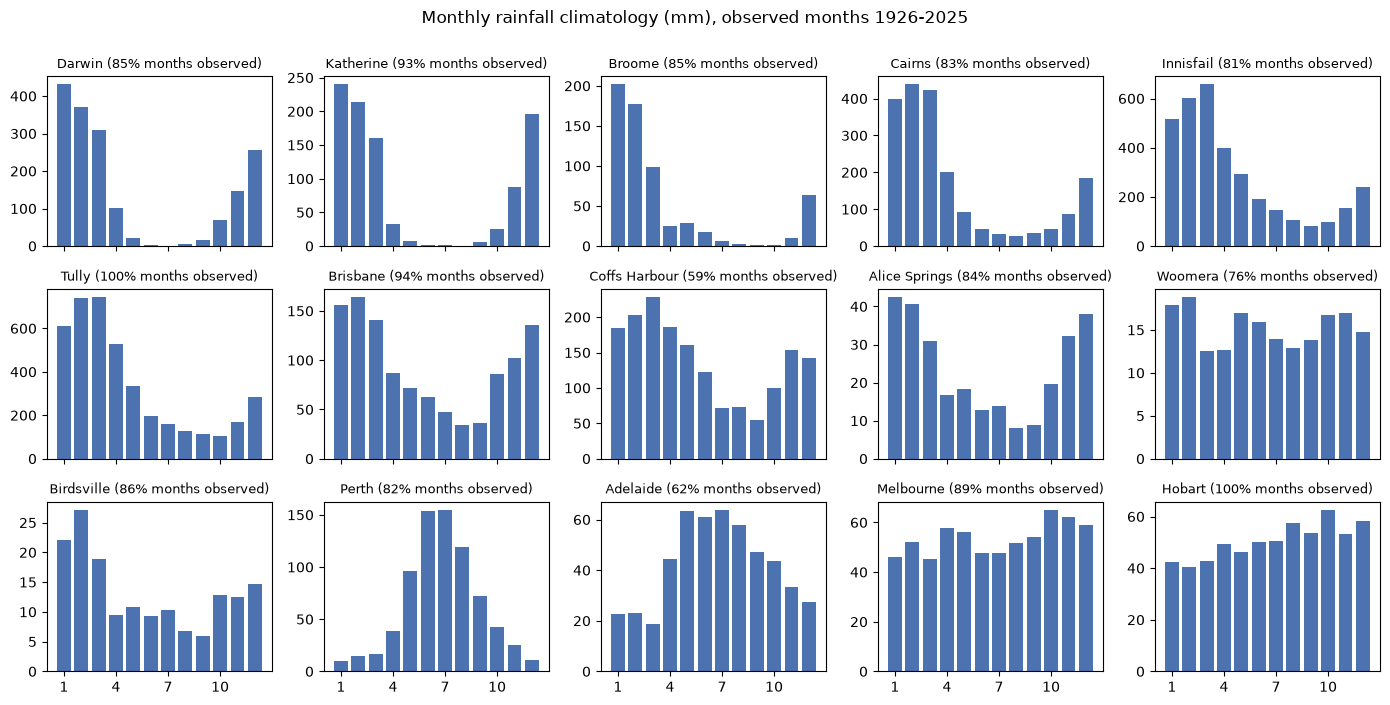

In [4]:
MON = json.load(open(PROCESSED / "monthly_15.json"))
fig, axes = plt.subplots(3, 5, figsize=(14, 7), sharex=True)
for ax, (st, s) in zip(axes.ravel(), MON["stations"].items()):
    y, ok = np.array(s["rain"]), np.array(s["ok"], bool); mon = np.arange(1200) % 12
    ax.bar(range(1, 13), [y[(mon == m) & ok].mean() for m in range(12)], color="#4c72b0")
    ax.set_title(f"{st.replace('_', ' ')} ({100 * ok.mean():.0f}% months observed)", fontsize=9); ax.set_xticks([1, 4, 7, 10])
fig.suptitle("Monthly rainfall climatology (mm), observed months 1926-2025", y=1.0); plt.tight_layout(); plt.show()

## 2. Climate indices

- **Niño3.4**: ERSST v5. For 1926–1949 the 5°N–5°S, 190°–240°E box mean is computed from the NCEI grid files (`ersst_v5_ncei_1921_1939.zip`, `ersst_v5_ncei_1940_1960.zip`); from 1950 the CPC series (`ersst5_nino_cpc.ascii`) is used. Anomalies are relative to the 1926–1960 climatology.
- **DMI**: Dipole Mode Index from HadISST (NOAA PSL, `dmi_had.txt`).
- **SOI**: Southern Oscillation Index, Climatic Research Unit (`soi_cru.dat`).

To mimic the data release schedule, the models use Niño3.4 and DMI only up to month *o* − 2 and SOI up to month *o* − 1 (*o* = first target month).

Nino3.4 grid vs CPC, overlap 132 months: r = 0.99997 | max difference = 0.024 degC
missing values: {'nino34': 0, 'dmi': 0, 'soi': 0}
climate_indices_1926_2025.csv identical to the repository version


,count,mean,std,min,25%,50%,75%,max
nino34,1200.0,0.26,0.87,-1.86,-0.36,0.18,0.78,3.45
dmi,1200.0,-0.15,0.35,-1.57,-0.38,-0.16,0.05,1.28
soi,1200.0,-0.07,1.06,-3.46,-0.75,-0.04,0.64,3.06


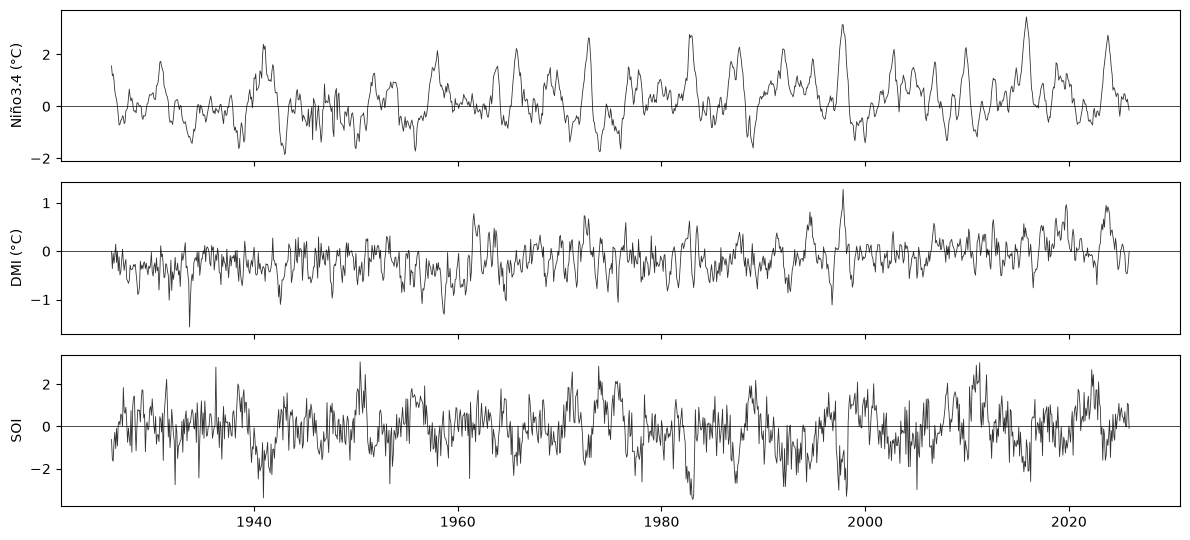

In [5]:
from climate_indices import compute_indices
previous = read_bytes(PROCESSED / "climate_indices_1926_2025.csv")
if REBUILD_DATA:
    compute_indices()
    print("climate_indices_1926_2025.csv", compare(PROCESSED / "climate_indices_1926_2025.csv", previous))
IDX = pd.read_csv(PROCESSED / "climate_indices_1926_2025.csv", index_col=0)
display(IDX.describe().round(2).T)
fig, axes = plt.subplots(3, 1, figsize=(12, 5.5), sharex=True)
t = pd.PeriodIndex(IDX.index, freq="M").to_timestamp()
for ax, c, lab in zip(axes, ["nino34", "dmi", "soi"], ["Niño3.4 (°C)", "DMI (°C)", "SOI"]):
    ax.plot(t, IDX[c], lw=0.6, color="#333333"); ax.axhline(0, color="k", lw=0.5); ax.set_ylabel(lab)
plt.tight_layout(); plt.show()

## 3. Base models with rolling retraining

Every station has nine base models:

| Paradigm | Model | Inputs |
|---|---|---|
| Statistical | SARIMA(2,1,2)(1,1,1)<sub>12</sub> | rainfall series |
| Machine learning | SVR (RBF), XGBoost | 12 rainfall lags, 6 lags of each climate index, sine–cosine of the target month; one model per horizon |
| Deep learning | LSTM, GRU (64 units) | 12-month sequence (rainfall, indices, month); all 4 horizons output at once |
| Hybrid | XGBoost-VMD, XGBoost-WT, LSTM-VMD, LSTM-WT | rainfall lags replaced by 3 frequency bands from causal VMD or the à trous Haar wavelet |

All models are retrained every 5 years from January 1961 (13 times, last in January 2021) using only data before the refit point. Between two refits the parameters are frozen and forecasts are issued every month for horizons of 1, 3, 6, and 12 months. VMD is rerun at every origin on past data only. Two rolling climatologies (expanding and 30-year) complete the pool of 11 members.

Code: `src/base_models_rolling.py`. One station takes about 15 minutes on one CPU core.

In [6]:
if RETRAIN_BASE_MODELS:
    archive = RESULTS / f"archive_{time.strftime('%Y%m%d_%H%M%S')}"; archive.mkdir()
    for f in RESULTS.glob("base_models_*.npz"): shutil.move(str(f), archive / f.name)
    print("Previous outputs moved to", archive.name, "| training with", WORKERS, "parallel processes")
    run_script("run_all.py", "base")
fs = sorted(RESULTS.glob("base_models_*.npz")); print(len(fs), "base-model files available")
assert len(fs) == 15, "Base-model outputs are incomplete; run with RETRAIN_BASE_MODELS = True"

15 base-model files available


In [7]:
# Base-model performance in the 2015-2025 test: mean NSE across the 13 test stations, per horizon
from common import TE0, N, HORIZONS
TEST = [s for s in MON["stations"] if s not in ("Coffs_Harbour", "Melbourne")]
rows = []
for st in TEST:
    B = np.load(RESULTS / f"base_models_{st}.npz"); names = list(B["names"]) + ["Clim-expanding", "Clim-30yr"]
    c30 = np.where(np.isnan(B["clim30"]), B["clim"], B["clim30"])
    F = np.concatenate([B["F"], B["clim"][None], c30[None]])
    for j, h in enumerate(HORIZONS):
        T = B["orig"] + h - 1; k = (T >= TE0) & (T < N) & B["OK"][:, j]
        y = B["Y"][k, j]; den = np.sum((y - y.mean())**2)
        for i, nm in enumerate(names):
            rows.append({"station": st, "h": h, "model": nm, "NSE": 1 - np.sum((y - F[i, k, j])**2) / den})
NSE_BASE = pd.DataFrame(rows).groupby(["model", "h"])["NSE"].mean().unstack().round(3)
display(Markdown("**Mean NSE of the base models, test 2015-2025 (13 stations)**")); display(NSE_BASE)

**Mean NSE of the base models, test 2015-2025 (13 stations)**

h,1,3,6,12
model,,,,
Clim-30yr,0.300,0.300,0.300,0.300
Clim-expanding,0.320,0.320,0.320,0.320
GRU,0.338,0.325,0.321,0.294
LSTM,0.315,0.294,0.297,0.293
LSTM-VMD,0.320,0.303,0.295,0.308
LSTM-WT,0.319,0.299,0.282,0.297
SARIMA,0.319,0.321,0.320,0.319
SVR,0.275,0.256,0.235,0.244
XGBoost,0.236,0.237,0.201,0.169


## 4. Meta-dataset and meta-learner gates

For every station *s*, origin *o*, and horizon *h*, the gate receives:

- the scaled error history of the last 12 months for all 11 pool members (summarised by a 16-unit LSTM);
- the current member forecasts, the sine–cosine of the target month, 6 ENSO/IOD regime features, and a one-hot horizon vector.

The gate produces convex weights through a softmax:

$$\mathbf{w}_{s,o,h}=\mathrm{softmax}(\mathbf{V}\mathbf{z}_{s,o,h}+\mathbf{b}),\qquad \hat{y}^{G}_{s,o,h}=\sum_{m=1}^{M} w_{m,s,o,h}\,\hat{y}_{m,s,o,h}$$

| Gate | Training data | Extra inputs | NNLS anchor |
|---|---|---|---|
| L-G3 | one station | – | no |
| L-G4 | one station | – | yes (per station) |
| GG3 | 15 stations | station embedding (dim. 4) + 6 static features | no |
| GG4 | 15 stations | station embedding + static features | yes (per station) |
| GG4-T | 12 stations (5 group folds) | static features only | yes (pooled over training stations) |

Meta-training uses target months 1962–2009, early stopping uses 2010–2014, and the test is 2015–2025. Every gate is trained with 3 seeds and the forecasts are averaged. Code: `src/meta_gate.py`.

The meta-dataset (≈ 58 MB) is not stored in the repository because it can be rebuilt from the base-model outputs in seconds.

In [8]:
run_script("meta_gate.py", "build")
Z = np.load(RESULTS / "meta_dataset.npz")
split = np.where(Z["T"] < 1008, "meta-training 1962-2009", np.where(Z["T"] < 1068, "validation 2010-2014", "test 2015-2025"))
tab = pd.crosstab(pd.Series(split, name="period"), pd.Series(np.where(Z["ok"], "observed", "not observed"), name="target"), margins=True, margins_name="total")
display(tab.loc[["meta-training 1962-2009", "validation 2010-2014", "test 2015-2025", "total"]])
print("Pool (11 members):", ", ".join(map(str, Z["pool"])))

build Darwin 3032
build Katherine 6064


build Broome 9096
build Cairns 12128


build Innisfail 15160
build Tully 18192


build Brisbane 21224
build Coffs_Harbour 24256


build Alice_Springs 27288
build Woomera 30320


build Birdsville 33352
build Perth 36384


build Adelaide 39416
build Melbourne 42448


build Hobart 45480


target,not observed,observed,total
period,,,
meta-training 1962-2009,2800,31160,33960
validation 2010-2014,508,3092,3600
test 2015-2025,1824,6096,7920
total,5132,40348,45480


Pool (11 members): SARIMA, SVR, XGBoost, XGBoost-VMD, XGBoost-WT, LSTM, GRU, LSTM-VMD, LSTM-WT, Clim-expanding, Clim-30yr


In [9]:
if RETRAIN_GATES:
    archive = RESULTS / f"archive_gates_{time.strftime('%Y%m%d_%H%M%S')}"; archive.mkdir()
    for f in RESULTS.glob("pred_*.npz"): shutil.move(str(f), archive / f.name)
    print("Previous gate predictions moved to", archive.name)
    run_script("run_all.py", "meta")
print("Gate predictions available:", len(list(RESULTS.glob("pred_local_*.npz"))), "local,", len(list(RESULTS.glob("pred_global_*.npz"))), "global,",
      len(list(RESULTS.glob("pred_transfer_*.npz"))), "transfer")

Gate predictions available: 15 local, 2 global, 5 transfer


## 5. Evaluation

- **NSE** per station, horizon, and period (2015–2025, 2015–2020, 2021–2025).
- **DM tests** per station with the Harvey–Leybourne–Newbold correction, then the Holm correction over the 52 station–horizon combinations.
- **Panel DM tests**: at every target month the scaled squared-error differences are averaged across stations, and the DM test is applied to that averaged series. The *p*-values are Holm-corrected over the four horizons.
- **Ensemble-suitability diagnostics** on the pre-test data 1962–2014.

Static benchmarks: the simple mean of the 9 base models (Mean), per station–horizon NNLS stacking (weights from 1962–2014), the best pre-test model, and the 30-year rolling climatology (Clim30). Code: `src/evaluate.py`.

In [10]:
previous = read_bytes(RESULTS / "evaluation_results.json")
run_script("evaluate.py")
print("\nevaluation_results.json", compare(RESULTS / "evaluation_results.json", previous))


== Mean NSE across test stations, 2015-2025
h=1 (13 stations) {'Clim-30yr': 0.3, 'Clim-expanding': 0.32, 'Mean': 0.339, 'NNLS': 0.33, 'Best model': 0.326, 'L-G3': 0.326, 'L-G4': 0.332, 'GG3': 0.34, 'GG4': 0.336, 'GG4-transfer': 0.338}
h=3 (13 stations) {'Clim-30yr': 0.3, 'Clim-expanding': 0.32, 'Mean': 0.326, 'NNLS': 0.327, 'Best model': 0.318, 'L-G3': 0.329, 'L-G4': 0.33, 'GG3': 0.34, 'GG4': 0.331, 'GG4-transfer': 0.332}
h=6 (13 stations) {'Clim-30yr': 0.3, 'Clim-expanding': 0.32, 'Mean': 0.31, 'NNLS': 0.322, 'Best model': 0.323, 'L-G3': 0.323, 'L-G4': 0.321, 'GG3': 0.333, 'GG4': 0.324, 'GG4-transfer': 0.329}
h=12 (13 stations) {'Clim-30yr': 0.3, 'Clim-expanding': 0.32, 'Mean': 0.308, 'NNLS': 0.321, 'Best model': 0.323, 'L-G3': 0.321, 'L-G4': 0.322, 'GG3': 0.329, 'GG4': 0.324, 'GG4-transfer': 0.324}

== Mean NSE across test stations, 2015-2020
h=1 (13 stations) {'Clim-30yr': 0.259, 'Clim-expanding': 0.291, 'Mean': 0.317, 'NNLS': 0.317, 'Best model': 0.311, 'L-G3': 0.311, 'L-G4': 0.31


evaluation_results.json newly created


## 5b. RMSE, MAE, and tests with absolute errors

NSE and MSE skill are scale-free, so they are used to average across stations whose rainfall differs greatly (Tully ≈ 342 mm/month, Birdsville ≈ 14 mm/month). For interpretation in rainfall units the following are also reported:

$$\mathrm{RMSE}=\sqrt{\frac{1}{T}\sum_t (y_t-\hat{y}_t)^2},\qquad \mathrm{MAE}=\frac{1}{T}\sum_t |y_t-\hat{y}_t|,\qquad \mathrm{SS}_{\mathrm{MAE}}=1-\frac{\mathrm{MAE}}{\mathrm{MAE}_{\mathrm{Clim30}}}$$

- RMSE is based on squared errors like NSE and the gate loss, so the ranking of methods per station is the same as with NSE.
- MAE weights all months equally and is therefore less affected by large errors in wet months. MAE skill is computed per station and then averaged.
- The panel DM test is repeated with scaled absolute-error differences, (|*e*<sup>A</sup>| − |*e*<sup>B</sup>|)/σ<sub>s</sub>, as a robustness check on the choice of loss function.

This analysis was added after the main results were obtained and is therefore exploratory. Code: `src/evaluate_errors.py`.

In [11]:
previous = read_bytes(RESULTS / "error_metrics.json")
run_script("evaluate_errors.py")
print("\nerror_metrics.json", compare(RESULTS / "error_metrics.json", previous))

== Mean RMSE and MAE across stations (mm), 2015-2025
h= 1  RMSE: {'Clim-30yr': 89.07, 'Mean': 88.04, 'NNLS': 88.52, 'L-G3': 88.48, 'GG3': 87.13, 'GG4-transfer': 87.59}
      MAE : {'Clim-30yr': 57.52, 'Mean': 57.3, 'NNLS': 57.84, 'L-G3': 57.39, 'GG3': 56.4, 'GG4-transfer': 56.82}
h= 3  RMSE: {'Clim-30yr': 89.07, 'Mean': 88.63, 'NNLS': 88.55, 'L-G3': 87.95, 'GG3': 87.21, 'GG4-transfer': 87.84}
      MAE : {'Clim-30yr': 57.52, 'Mean': 57.84, 'NNLS': 57.8, 'L-G3': 56.98, 'GG3': 56.59, 'GG4-transfer': 57.22}
h= 6  RMSE: {'Clim-30yr': 89.07, 'Mean': 89.58, 'NNLS': 88.75, 'L-G3': 88.28, 'GG3': 87.52, 'GG4-transfer': 88.04}
      MAE : {'Clim-30yr': 57.52, 'Mean': 59.26, 'NNLS': 58.17, 'L-G3': 57.55, 'GG3': 57.0, 'GG4-transfer': 57.42}
h=12  RMSE: {'Clim-30yr': 89.07, 'Mean': 89.82, 'NNLS': 88.69, 'L-G3': 88.86, 'GG3': 88.1, 'GG4-transfer': 88.4}
      MAE : {'Clim-30yr': 57.52, 'Mean': 59.62, 'NNLS': 57.93, 'L-G3': 58.5, 'GG3': 57.41, 'GG4-transfer': 57.79}

== Panel DM 2015-2025, Holm p (sq


error_metrics.json newly created


In [12]:
import importlib, manuscript_tables_figures as MT
importlib.reload(MT)
G = json.load(open(RESULTS / "error_metrics.json"))
MET = {"Clim-30yr": "Clim30", "Mean": "Mean", "NNLS": "NNLS", "L-G3": "L-G3", "GG3": "GG3", "GG4-transfer": "GG4-T"}
for per, n in [("2015-2025", 13), ("2021-2025", 11)]:
    for meas, lab, f in [("RMSE", "Mean RMSE (mm)", "{:.2f}"), ("MAE", "Mean MAE (mm)", "{:.2f}"), ("skill_MAE", "MAE skill vs Clim30", "{:.1%}")]:
        t = pd.DataFrame({MET[m]: [G["mean"][per][str(h)][m][meas] for h in [1, 3, 6, 12]] for m in MET}, index=pd.Index([1, 3, 6, 12], name="h"))
        if meas == "skill_MAE": t = t.drop(columns="Clim30")
        best = t.idxmax(axis=1) if meas == "skill_MAE" else t.idxmin(axis=1)
        display(Markdown(f"**{lab}, test {per} ({n} stations)** — bold = best"))
        display(t.style.format(f).apply(lambda r: ["font-weight: bold" if c == best[r.name] else "" for c in r.index], axis=1))
display(Markdown("**GG3 per station–horizon by MAE, and Holm p of the panel DM test for both loss functions (test 2015–2025)**"))
display(MT.error_figures())

**Mean RMSE (mm), test 2015-2025 (13 stations)** — bold = best

,Clim30,Mean,NNLS,L-G3,GG3,GG4-T
h,,,,,,
1,89.07,88.04,88.52,88.48,87.13,87.59
3,89.07,88.63,88.55,87.95,87.21,87.84
6,89.07,89.58,88.75,88.28,87.52,88.04
12,89.07,89.82,88.69,88.86,88.10,88.40


**Mean MAE (mm), test 2015-2025 (13 stations)** — bold = best

,Clim30,Mean,NNLS,L-G3,GG3,GG4-T
h,,,,,,
1,57.52,57.30,57.84,57.39,56.40,56.82
3,57.52,57.84,57.80,56.98,56.59,57.22
6,57.52,59.26,58.17,57.55,57.00,57.42
12,57.52,59.62,57.93,58.50,57.41,57.79


**MAE skill vs Clim30, test 2015-2025 (13 stations)** — bold = best

,Mean,NNLS,L-G3,GG3,GG4-T
h,,,,,
1,0.6%,-0.2%,0.6%,2.0%,1.2%
3,-0.6%,-0.2%,1.1%,1.8%,0.3%
6,-2.5%,-0.6%,0.4%,1.0%,0.3%
12,-3.1%,-0.4%,-0.6%,0.7%,-0.4%


... (4 outputs left out)

**MAE skill vs Clim30, test 2021-2025 (11 stations)** — bold = best

,Mean,NNLS,L-G3,GG3,GG4-T
h,,,,,
1,-1.5%,-2.8%,-1.7%,0.5%,0.0%
3,-2.4%,-2.0%,-0.7%,0.4%,-0.4%
6,-3.1%,-1.1%,0.1%,-0.1%,-0.0%
12,-3.6%,-1.1%,-0.9%,0.5%,-0.3%


**GG3 per station–horizon by MAE, and Holm p of the panel DM test for both loss functions (test 2015–2025)**

,MAE wins (of 52),median MAE reduction (%),"p Holm squared error (h=1,3,6,12)","p Holm absolute error (h=1,3,6,12)"
GG3 vs L-G3,33,0.7,"[0.008, 0.009, 0.033, 0.169]","[0.005, 0.158, 0.182, 0.116]"
GG3 vs NNLS,33,1.0,"[0.135, 0.005, 0.243, 0.588]","[0.003, 0.008, 0.07, 0.115]"
GG3 vs Clim30,39,1.1,"[0.006, 0.006, 0.054, 0.086]","[0.156, 0.312, 1.0, 1.0]"
GG3 vs Mean,47,2.3,"[0.44, 0.07, 0.035, 0.127]","[0.064, 0.018, 0.0, 0.0]"
GG4-T vs Clim30,27,0.2,"[0.026, 0.081, 0.092, 0.171]","[0.932, 1.0, 1.0, 0.614]"


## 6. Manuscript tables

In [13]:
import importlib, manuscript_tables_figures as MT
importlib.reload(MT)
T = MT.all_tables()
titles = {"table1_stations": "Table 1. Study stations", "table2_nse_mean": "Table 2. Mean NSE across test stations",
          "table3_dm_panel": "Table 3. Cross-station panel Diebold-Mariano tests (DM and Holm-corrected p over 4 horizons; negative DM = first method more accurate)",
          "table4_rmse_mae": "Table 4. RMSE, MAE (mm), and MAE skill vs Clim30 (%), mean across stations, test 2015-2025",
          "table5_dm_absolute_error": "Table 5. Panel Diebold-Mariano tests with absolute errors (DM and Holm-corrected p over 4 horizons)",
          "table6_nse_stations": "Table 6. NSE per station, mean of the four horizons, test 2015-2025"}
dmfmt = lambda k: {c: ("{:.2f}" if c.startswith("DM") else "{:.3f}") for c in T[k].columns if c.startswith(("DM", "p Holm"))}
fmt = {"table1_stations": {"Latitude": "{:.2f}", "Longitude": "{:.2f}", "Rainfall (mm/month)": "{:.1f}", "n test (h=1)": "{:.0f}"},
       "table3_dm_panel": dmfmt("table3_dm_panel"), "table5_dm_absolute_error": dmfmt("table5_dm_absolute_error"),
       "table4_rmse_mae": {c: "{:.2f}" for c in ["Clim30", "Mean", "NNLS", "L-G3", "GG3", "GG4-T"]}}
for k, v in T.items():
    display(Markdown(f"**{titles[k]}**")); display(v.style.hide(axis="index").format(fmt.get(k), precision=3, na_rep="–"))
print("CSV files saved in reports/manuscript/")

**Table 1. Study stations**

Station,BoM ID,Climate,Latitude,Longitude,Rainfall (mm/month),n test (h=1)
Darwin,014015,Tropis bermusim,-12.42,130.89,140.3,132
Katherine,014902,Tropis bermusim,-14.46,132.26,82.9,125
Broome,003003,Tropis semi-kering bermusim,-17.95,122.24,52.2,131
Cairns,031011,Tropis basah,-16.87,145.75,173.6,127
Innisfail,032025,Tropis basah,-17.52,146.03,298.0,66
Tully,032042,Tropis basah,-17.94,145.93,341.8,132
Brisbane,040214,Subtropis pesisir,-27.48,153.03,93.7,130
Coffs Harbour,059040,Subtropis pesisir,-30.31,153.12,141.8,–
Alice Springs,015590,Pedalaman kering,-23.80,133.89,22.5,129
Woomera,016001,Pedalaman kering,-31.16,136.81,14.7,128


**Table 2. Mean NSE across test stations**

Period,h,Clim30,Mean,NNLS,L-G3,GG3,GG4-T
Test 2015-2025 (13 stations),1,0.300,0.339,0.330,0.326,0.340,0.338
Test 2015-2025 (13 stations),3,0.300,0.326,0.327,0.329,0.340,0.332
Test 2015-2025 (13 stations),6,0.300,0.310,0.322,0.323,0.333,0.329
Test 2015-2025 (13 stations),12,0.300,0.308,0.321,0.321,0.329,0.324
Test 2015-2020 (13 stations),1,0.259,0.317,0.317,0.311,0.321,0.315
Test 2015-2020 (13 stations),3,0.259,0.296,0.305,0.308,0.318,0.302
Test 2015-2020 (13 stations),6,0.259,0.272,0.302,0.296,0.310,0.301
Test 2015-2020 (13 stations),12,0.259,0.268,0.301,0.290,0.303,0.294
Test 2021-2025 (11 stations),1,0.375,0.377,0.364,0.369,0.387,0.388
Test 2021-2025 (11 stations),3,0.375,0.369,0.371,0.372,0.389,0.386


**Table 3. Cross-station panel Diebold-Mariano tests (DM and Holm-corrected p over 4 horizons; negative DM = first method more accurate)**

Period,Comparison,DM h=1,p Holm h=1,DM h=3,p Holm h=3,DM h=6,p Holm h=6,DM h=12,p Holm h=12
2015-2025,GG3 vs L-G3,-3.14,0.008,-3.03,0.009,-2.43,0.033,-1.38,0.169
2015-2025,GG4 vs L-G4,-2.59,0.043,-0.99,0.324,-1.68,0.189,-2.20,0.088
2015-2025,GG3 vs NNLS,-2.03,0.135,-3.29,0.005,-1.56,0.243,-0.54,0.588
2015-2025,GG3 vs Mean,-0.77,0.440,-2.29,0.070,-2.66,0.035,-1.87,0.127
2015-2025,GG3 vs Clim30,-3.14,0.006,-3.25,0.006,-2.24,0.054,-1.73,0.086
2015-2025,L-G4 vs NNLS,0.03,1.000,-0.15,1.000,0.61,1.000,0.04,1.000
2015-2025,GG4-T vs GG4,-1.41,0.633,-1.28,0.633,-1.42,0.633,-0.02,0.984
2015-2025,GG4-T vs Clim30,-2.76,0.026,-2.23,0.081,-2.01,0.092,-1.38,0.171
2021-2025,GG3 vs L-G3,-2.64,0.032,-2.88,0.022,-1.27,0.420,-0.82,0.420
2021-2025,GG3 vs NNLS,-2.73,0.017,-3.35,0.004,-5.61,0.000,-1.82,0.074


... (3 outputs left out)

Period,Comparison,DM h=1,p Holm h=1,DM h=3,p Holm h=3,DM h=6,p Holm h=6,DM h=12,p Holm h=12
2015-2025,GG3 vs L-G3,-3.32,0.005,-1.77,0.158,-1.34,0.182,-2.09,0.116
2015-2025,GG3 vs NNLS,-3.43,0.003,-3.08,0.008,-2.13,0.070,-1.59,0.115
2015-2025,GG3 vs Mean,-1.87,0.064,-2.65,0.018,-4.33,0.000,-4.10,0.000
2015-2025,GG3 vs Clim30,-2.09,0.156,-1.64,0.312,-0.66,1.000,-0.61,1.000
2015-2025,GG4-T vs Clim30,-1.02,0.932,0.24,1.000,0.10,1.000,1.44,0.614
2021-2025,GG3 vs L-G3,-3.09,0.012,-2.20,0.094,0.47,0.641,-1.64,0.211
2021-2025,GG3 vs NNLS,-2.96,0.018,-2.11,0.118,-1.10,0.281,-1.49,0.281
2021-2025,GG3 vs Clim30,-0.21,1.000,-0.05,1.000,0.38,1.000,-0.18,1.000


**Table 6. NSE per station, mean of the four horizons, test 2015-2025**

Station,n test (h=1),Clim30,Mean,NNLS,L-G3,GG3,GG4-T
Darwin,132,0.699,0.686,0.681,0.698,0.708,0.699
Katherine,125,0.547,0.567,0.536,0.570,0.570,0.569
Broome,131,0.361,0.362,0.378,0.367,0.373,0.369
Cairns,127,0.475,0.466,0.476,0.480,0.493,0.486
Innisfail,66,0.312,0.314,0.320,0.332,0.343,0.331
Tully,132,0.466,0.461,0.475,0.468,0.480,0.474
Brisbane,130,0.176,0.186,0.188,0.155,0.191,0.203
Alice Springs,129,0.159,0.137,0.152,0.146,0.144,0.144
Woomera,128,0.010,0.001,-0.010,0.002,0.007,0.005
Birdsville,51,-0.203,0.025,0.003,-0.020,-0.007,-0.004


CSV files saved in reports/manuscript/


## 7. Manuscript figures

**Figure 1. Research framework**

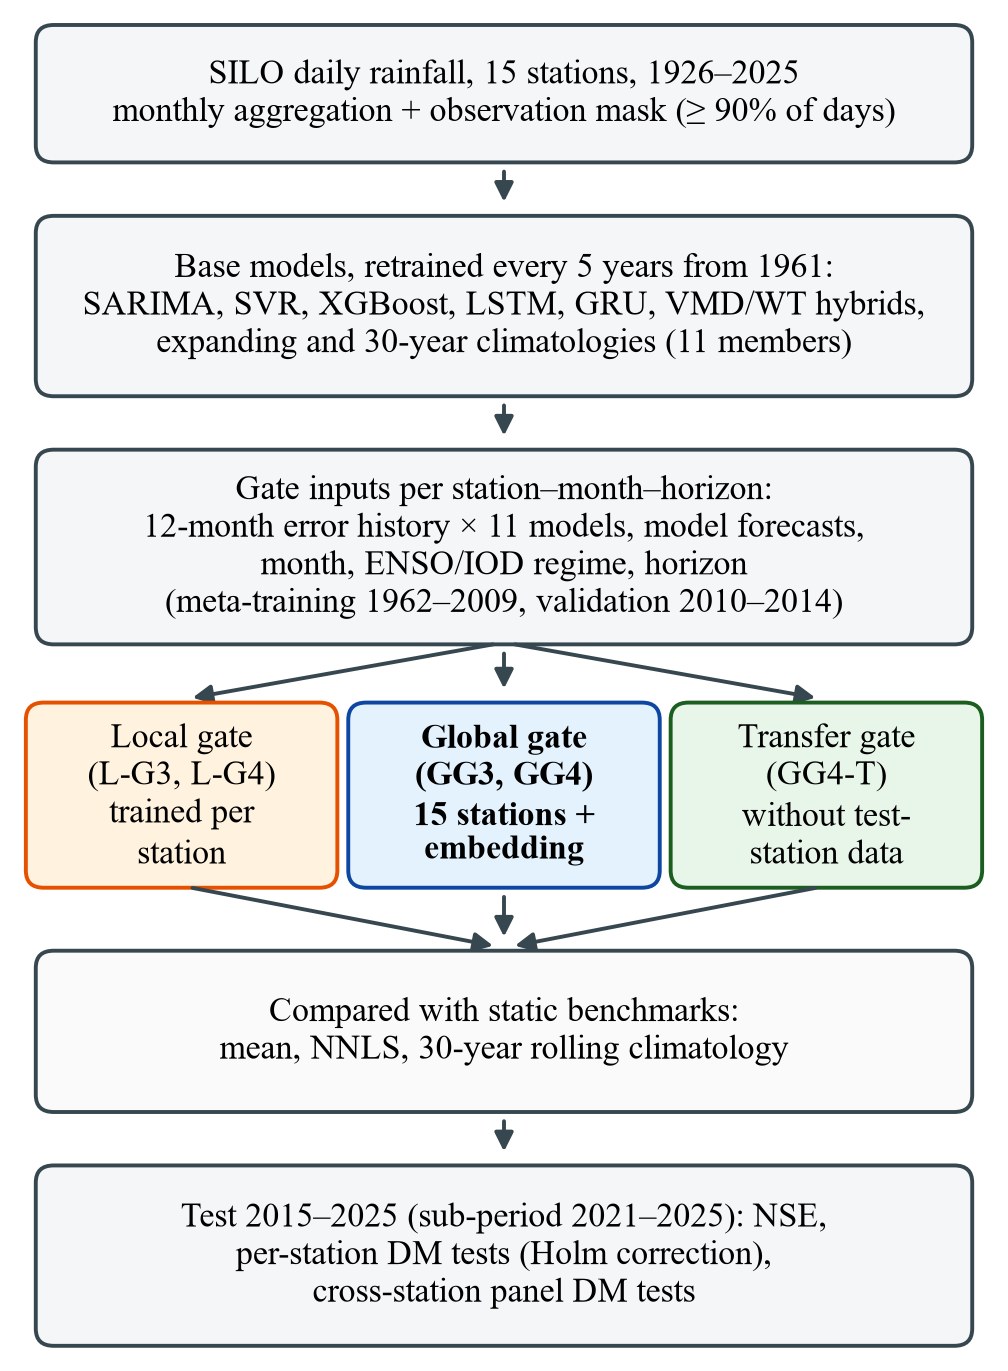

**Figure 2. MSE skill relative to Clim30 per horizon in the two test sub-periods**

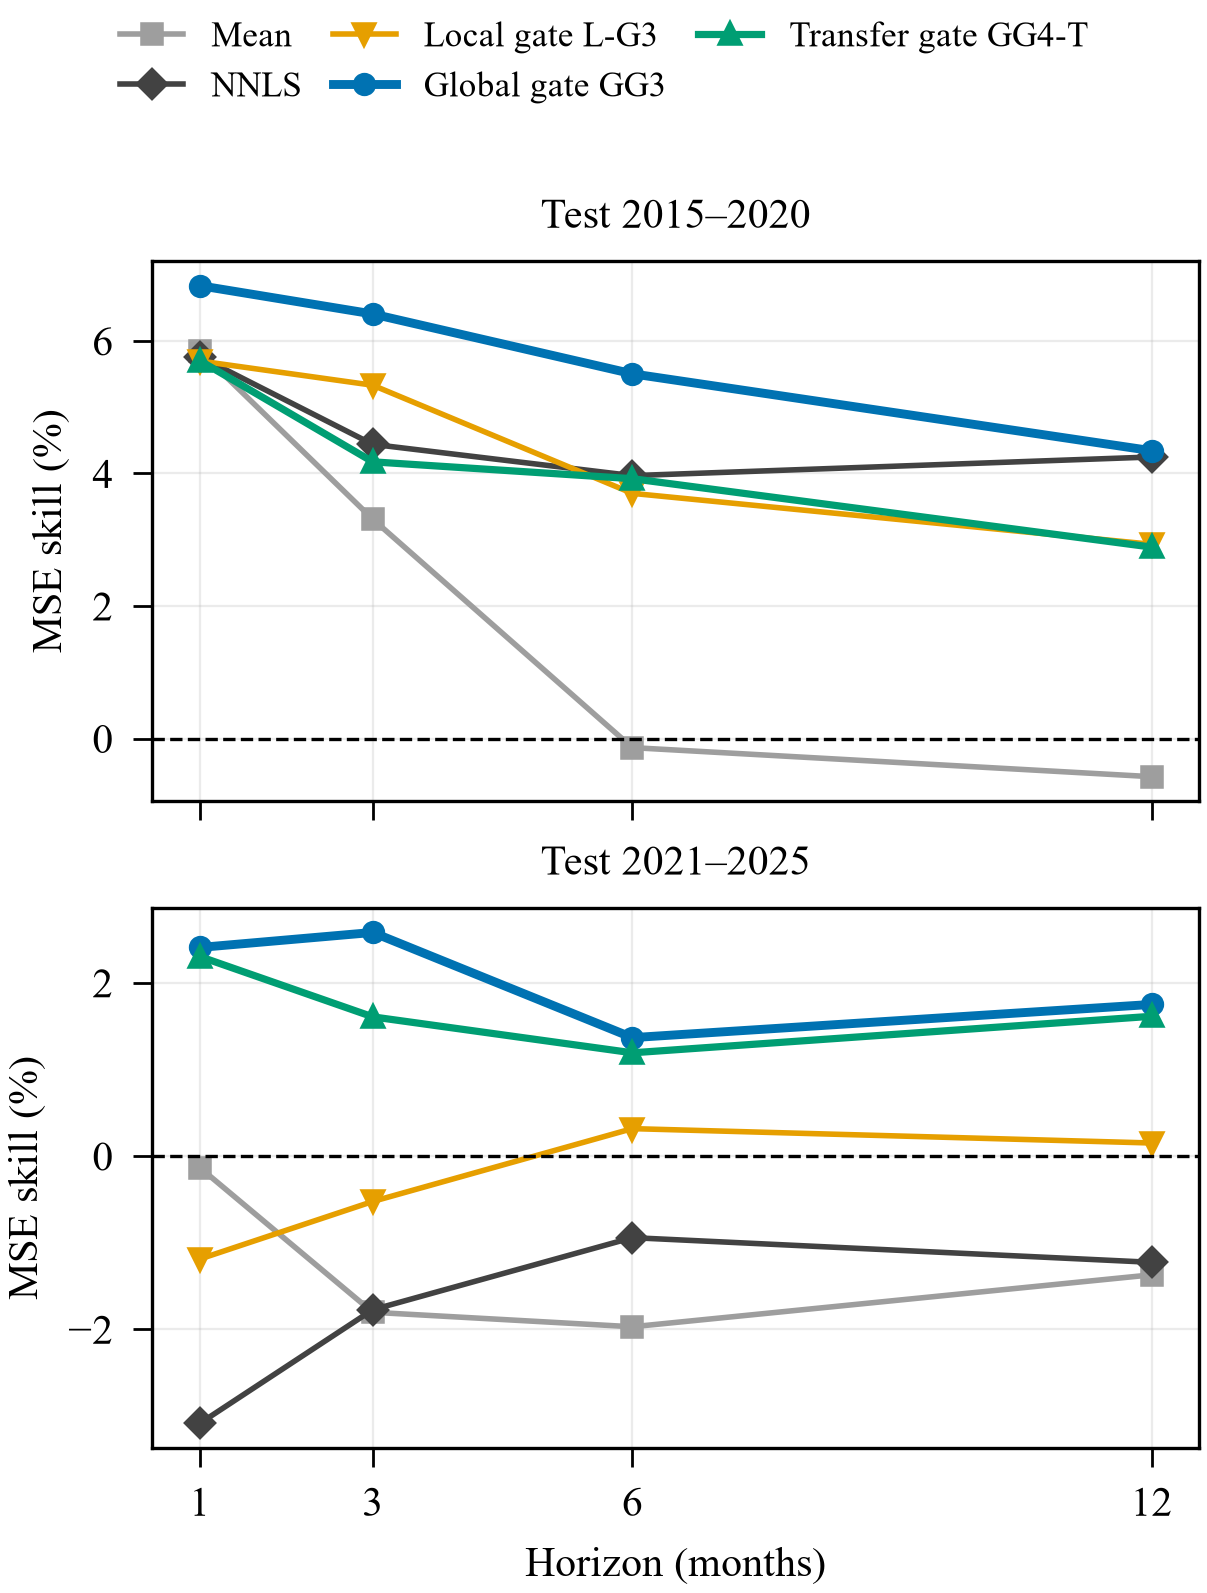

**Figure 3. MSE reduction (%) of GG3 per station and horizon: (a) vs L-G3, (b) vs NNLS; * = p < 0.05 before the Holm correction**

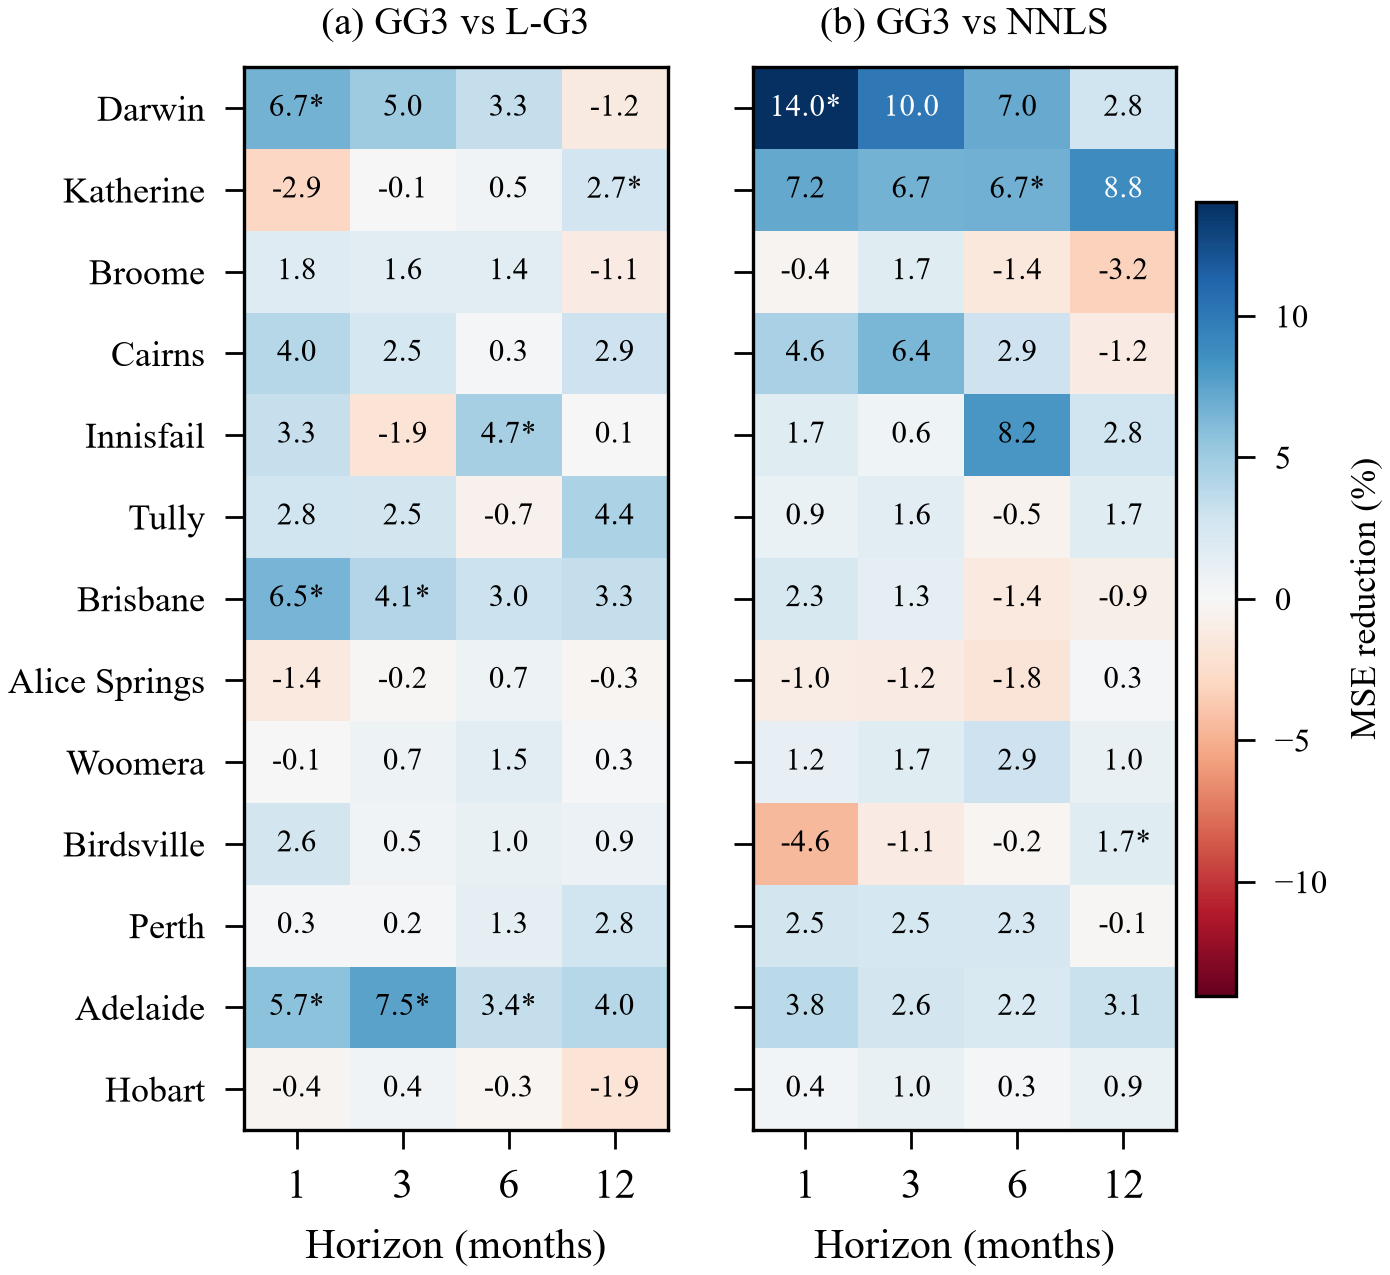

**Figure 4. Mean GG3 weight per model family by target month, Darwin and Perth (h = 1)**

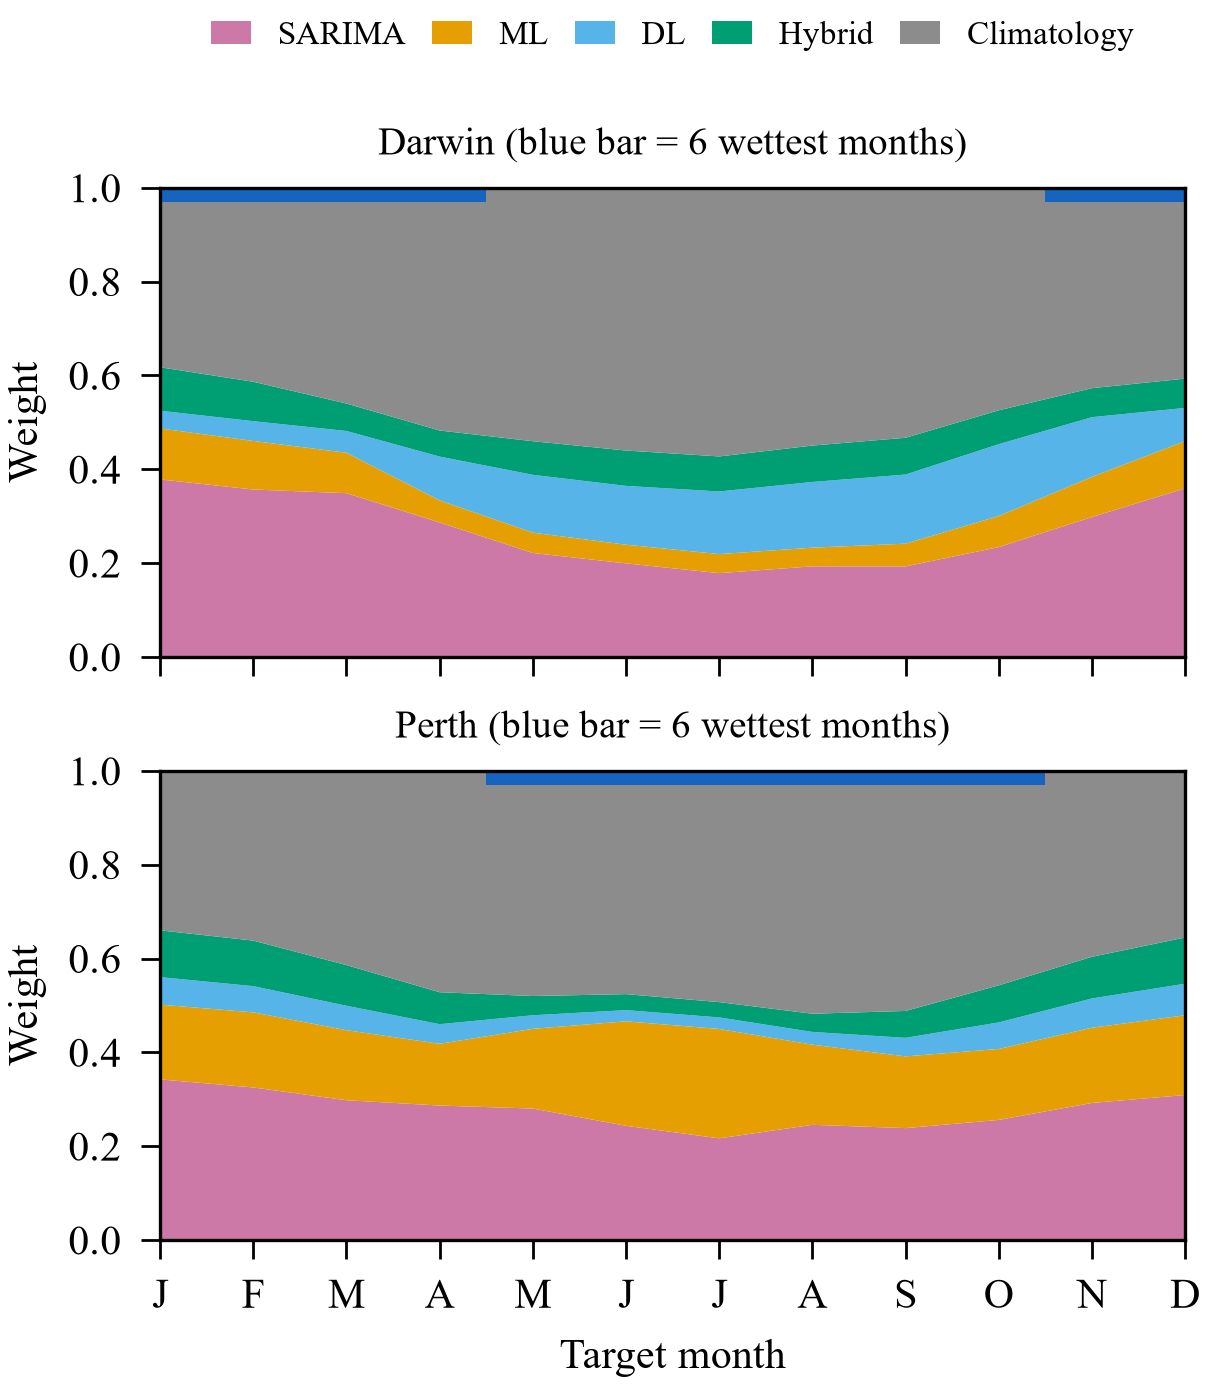

In [14]:
MT.all_figures()
cap = {"figure1_framework.png": "Figure 1. Research framework",
       "figure2_skill.png": "Figure 2. MSE skill relative to Clim30 per horizon in the two test sub-periods",
       "figure3_heatmap.png": "Figure 3. MSE reduction (%) of GG3 per station and horizon: (a) vs L-G3, (b) vs NNLS; * = p < 0.05 before the Holm correction",
       "figure4_weights.png": "Figure 4. Mean GG3 weight per model family by target month, Darwin and Perth (h = 1)"}
for f, c in cap.items():
    display(Markdown(f"**{c}**")); display(Image(filename=str(ROOT / "reports" / "manuscript" / f), width=460))

## 8. Full experiment report

All pairwise comparisons, panel DM tests for the three periods, wins/losses per station, ensemble-suitability diagnostics, and gate weights. The outputs are written to `reports/experiment/` (CSV, `tables_global_gate.xlsx`, and figures). Code: `src/experiment_report.py`.

In [15]:
run_script("experiment_report.py")


== nse_mean
   Period  h  n stations  Climatology 30 yr  Expanding climatology  Mean  NNLS  Best model  Local gate G3  Local gate G4  Global gate GG3  Global gate GG4  Global transfer gate
2015-2025  1          13              0.300                  0.320 0.339 0.330       0.326          0.326          0.332            0.340            0.336                 0.338
2015-2025  3          13              0.300                  0.320 0.326 0.327       0.318          0.329          0.330            0.340            0.331                 0.332
2015-2025  6          13              0.300                  0.320 0.310 0.322       0.323          0.323          0.321            0.333            0.324                 0.329
2015-2025 12          13              0.300                  0.320 0.308 0.321       0.323          0.321          0.322            0.329            0.324                 0.324
2015-2020  1          13              0.259                  0.291 0.317 0.317       0.311          0.

## 9. Check of the figures quoted in the manuscript

This cell compares the evaluation results with the figures quoted in the manuscript. In reproduction mode every line should show ✓. After retraining, small differences can appear because of hardware or library-version differences.

In [16]:
R = json.load(open(RESULTS / "evaluation_results.json")); P = R["panel"]
def ph(c, per, h): return round(P[c][f"{per} h={h}"]["p_holm_horizon"], 3)
def nse(per, m): return [round(R["nse_mean"][per][h][m], 3) for h in ["1", "3", "6", "12"]]
CHECKS = [
    ("NSE GG3 2015-2025 (h=1,3,6,12)", nse("2015-2025", "GG3"), [0.340, 0.340, 0.333, 0.329]),
    ("NSE GG4-T 2015-2025", nse("2015-2025", "GG4-transfer"), [0.338, 0.332, 0.329, 0.324]),
    ("NSE Clim30 2021-2025", nse("2021-2025", "Clim-30yr"), [0.375, 0.375, 0.375, 0.375]),
    ("GG3 vs L-G3: panel Holm p h=1,3,6", [ph("GG3 vs L-G3", "2015-2025", h) for h in (1, 3, 6)], [0.008, 0.009, 0.033]),
    ("GG3 vs L-G3: wins of 52", R["wins"]["GG3 vs L-G3"]["better"], 39),
    ("GG4 vs L-G4: panel Holm p h=1", ph("GG4 vs L-G4", "2015-2025", 1), 0.043),
    ("GG3 vs Clim30: panel Holm p h=1,3", [ph("GG3 vs Clim-30yr", "2015-2025", h) for h in (1, 3)], [0.006, 0.006]),
    ("GG3 vs NNLS: panel Holm p h=3", ph("GG3 vs NNLS", "2015-2025", 3), 0.005),
    ("GG3 vs Mean: panel Holm p h=6", ph("GG3 vs Mean", "2015-2025", 6), 0.035),
    ("GG3 vs NNLS 2021-2025: Holm p h=1,3,6", [ph("GG3 vs NNLS", "2021-2025", h) for h in (1, 3, 6)], [0.017, 0.004, 0.0]),
    ("GG4-T vs Clim30: panel Holm p h=1", ph("GG4-transfer vs Clim-30yr", "2015-2025", 1), 0.026),
    ("GG4-T vs GG4: minimum Holm p", min(ph("GG4-transfer vs GG4", "2015-2025", h) for h in (1, 3, 6, 12)), 0.633),
    ("Wins GG3 vs NNLS / Clim30 / Mean", [R["wins"][c]["better"] for c in ["GG3 vs NNLS", "GG3 vs Clim-30yr", "GG3 vs Mean"]], [38, 43, 45]),
]
G = json.load(open(RESULTS / "error_metrics.json")); GP = G["panel"]
def pa(c, per, h): return round(GP[c][f"{per} h={h}"]["absolute"]["p_holm_horizon"], 3)
def gm(per, m, meas, d=2): return [round(G["mean"][per][str(h)][m][meas], d) for h in (1, 3, 6, 12)]
CHECKS += [
    ("RMSE GG3 2015-2025 (mm)", gm("2015-2025", "GG3", "RMSE"), [87.13, 87.21, 87.52, 88.10]),
    ("MAE GG3 2015-2025 (mm)", gm("2015-2025", "GG3", "MAE"), [56.40, 56.59, 57.00, 57.41]),
    ("MAE skill GG3 vs Clim30 2015-2025", gm("2015-2025", "GG3", "skill_MAE", 3), [0.020, 0.018, 0.010, 0.007]),
    ("Absolute error, GG3 vs L-G3: Holm p h=1", pa("GG3 vs L-G3", "2015-2025", 1), 0.005),
    ("Absolute error, GG3 vs NNLS: Holm p h=1,3", [pa("GG3 vs NNLS", "2015-2025", h) for h in (1, 3)], [0.003, 0.008]),
    ("Absolute error, GG3 vs Clim30: minimum Holm p", min(pa("GG3 vs Clim-30yr", "2015-2025", h) for h in (1, 3, 6, 12)), 0.156),
    ("Absolute error 2021-2025, GG3 vs L-G3 / NNLS: Holm p h=1", [pa("GG3 vs L-G3", "2021-2025", 1), pa("GG3 vs NNLS", "2021-2025", 1)], [0.012, 0.018]),
    ("MAE wins GG3 vs L-G3 / NNLS / Clim30 / Mean",
     [G["wins_mae"][c]["2015-2025"]["wins"] for c in ["GG3 vs L-G3", "GG3 vs NNLS", "GG3 vs Clim-30yr", "GG3 vs Mean"]], [33, 33, 39, 47]),
]
for name, value, manuscript in CHECKS:
    ok = np.allclose(np.atleast_1d(value).astype(float), np.atleast_1d(manuscript).astype(float), atol=5e-4)
    print("✓" if ok else "✗", f"{name}: result = {value} | manuscript = {manuscript}")
display(Markdown("**Key figures per comparison**")); display(MT.key_figures())

✓ NSE GG3 2015-2025 (h=1,3,6,12): result = [0.34, 0.34, 0.333, 0.329] | manuscript = [0.34, 0.34, 0.333, 0.329]
✓ NSE GG4-T 2015-2025: result = [0.338, 0.332, 0.329, 0.324] | manuscript = [0.338, 0.332, 0.329, 0.324]
✓ NSE Clim30 2021-2025: result = [0.375, 0.375, 0.375, 0.375] | manuscript = [0.375, 0.375, 0.375, 0.375]
✓ GG3 vs L-G3: panel Holm p h=1,3,6: result = [0.008, 0.009, 0.033] | manuscript = [0.008, 0.009, 0.033]
✓ GG3 vs L-G3: wins of 52: result = 39 | manuscript = 39
✓ GG4 vs L-G4: panel Holm p h=1: result = 0.043 | manuscript = 0.043
✓ GG3 vs Clim30: panel Holm p h=1,3: result = [0.006, 0.006] | manuscript = [0.006, 0.006]
✓ GG3 vs NNLS: panel Holm p h=3: result = 0.005 | manuscript = 0.005
✓ GG3 vs Mean: panel Holm p h=6: result = 0.035 | manuscript = 0.035
✓ GG3 vs NNLS 2021-2025: Holm p h=1,3,6: result = [0.017, 0.004, 0.0] | manuscript = [0.017, 0.004, 0.0]
✓ GG4-T vs Clim30: panel Holm p h=1: result = 0.026 | manuscript = 0.026
✓ GG4-T vs GG4: minimum Holm p: result 

**Key figures per comparison**

,wins (of 52),median MSE reduction (%),"p Holm panel 2015-2025 (h=1,3,6,12)","p Holm panel 2021-2025 (h=1,3,6,12)"
GG3 vs L-G3,39,1.4,"[0.008, 0.009, 0.033, 0.169]","[0.032, 0.022, 0.42, 0.42]"
GG3 vs NNLS,38,1.7,"[0.135, 0.005, 0.243, 0.588]","[0.017, 0.004, 0.0, 0.074]"
GG3 vs Clim-30yr,43,3.3,"[0.006, 0.006, 0.054, 0.086]","[0.775, 0.582, 0.846, 0.846]"
GG3 vs Mean,45,1.9,"[0.44, 0.07, 0.035, 0.127]","[1.0, 0.549, 1.0, 1.0]"
GG4 vs L-G4,33,0.1,"[0.043, 0.324, 0.189, 0.088]","[0.046, 0.821, 0.662, 0.848]"
GG4-transfer vs GG4,28,0.1,"[0.633, 0.633, 0.633, 0.984]","[0.516, 0.516, 0.516, 0.516]"
GG4-transfer vs Clim-30yr,38,2.2,"[0.026, 0.081, 0.092, 0.171]","[1.0, 1.0, 1.0, 1.0]"


## Notes

- The comparisons of GG3 with Mean, NNLS, and Clim30 were added after the initial results were seen, so the manuscript treats them as exploratory analyses. RMSE, MAE, and the absolute-error tests were also added after the main results were obtained.
- The base models are trained with one seed. The gates are trained with three seeds and averaged.
- Coffs Harbour and Melbourne have almost no observed months in 2015–2025, so they are used only to train the global gates and are not evaluated.
- Adelaide and Birdsville have no observed target months in the 2010–2014 validation period; their local gates use the last 20% of observed training targets for early stopping.
- **Reproducibility of retraining.** The outputs stored in `results/` are reproduced exactly by reproduction mode. When tested on another machine with the same library versions, the meta-dataset, the local gates, and the transfer gates were reproduced to float32 precision (differences < 10⁻⁶), and the base models other than SARIMA were reproduced too (SARIMA differs by ≈ 4% on average because statsmodels' optimiser is platform dependent). The global gate GG3 was not reproduced: its training is sensitive to small numerical differences between machines, which shifts *p*-values near the 0.05 threshold. In that test, GG3 vs L-G3 remained significant at *h* = 1 and 3 but no longer at *h* = 6 (Holm *p* 0.057), and the advantage over NNLS in 2021–2025 remained significant at *h* = 1 and 3 but not at *h* = 6. Increasing the number of gate seeds (environment variable `SEEDS`, e.g. `SEEDS=1,2,3,4,5,6,7,8,9,10`) reduces this sensitivity.